# LSTM one-month-ahead TWSA forecast with prediction intervals

Runs from `My Drive/DATA 255 Group Project/LSTM_Water_Storage_Forecast`. Three runs:

1. **GRACE-only, split files, test 2024-01 to 2025-12** (the original LSTM result).
2. **GRACE-only, aligned file, test 2024-01 to 2025-09** (team comparison).
3. **GRACE + precipitation + temperature, aligned file, test 2024-01 to 2025-09** (team comparison, early fusion).

Runs 2–3 need the team's aligned file `p_t_tws_aligned_0.5deg.nc`, either in `data/processed/` of this folder or reachable through a shortcut to the shared *Group Project* folder in My Drive. Use **Runtime → Change runtime type → T4 GPU** (about 4 minutes per run).

In [1]:
from google.colab import drive
drive.mount("/content/drive")

import os
FOLDER = "/content/drive/MyDrive/DATA 255 Group Project/LSTM_Water_Storage_Forecast"
os.chdir(FOLDER)

needed = ["scripts/lstm_forecast.py", "configs/lstm_config.yaml", "configs/lstm_aligned_grace.yaml",
          "configs/lstm_aligned_combined.yaml", "configs/grace_fo_config.yaml",
          "data/processed/grace_fo_train.nc", "data/processed/grace_fo_validation.nc",
          "data/processed/grace_fo_test.nc", "tests/test_lstm_forecast.py"]
missing = [f for f in needed if not os.path.exists(f)]
assert not missing, f"Missing in {FOLDER}: {missing}"

ALIGNED_CANDIDATES = [
    "data/processed/p_t_tws_aligned_0.5deg.nc",
    "/content/drive/MyDrive/Group Project/Intermediate Progress/Precipitation and Temperature analysis/processed/p_t_tws_aligned_0.5deg.nc",
]
ALIGNED = next((p for p in ALIGNED_CANDIDATES if os.path.exists(p)), None)
print("All input files found in", FOLDER)
print("Aligned file:", ALIGNED or "NOT FOUND (runs 2 and 3 will be skipped)")

Mounted at /content/drive
All input files found in /content/drive/MyDrive/DATA 255 Group Project/LSTM_Water_Storage_Forecast
Aligned file: data/processed/p_t_tws_aligned_0.5deg.nc


In [2]:
!pip -q install netCDF4
import torch
print("PyTorch", torch.__version__, "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (CPU)")

PyTorch 2.14.1+cu130 | GPU: Tesla T4


## Tests: leakage checks, metrics, interval calibration, missing-month handling

In [3]:
!python -m unittest discover -s tests -p test_lstm_forecast.py -v

test_conformal_factor_reaches_nominal_coverage (test_lstm_forecast.LSTMForecastTests.test_conformal_factor_reaches_nominal_coverage) ... ok
test_extra_inputs_use_training_statistics_only (test_lstm_forecast.LSTMForecastTests.test_extra_inputs_use_training_statistics_only) ... ok
test_inputs_precede_target_and_splits_do_not_mix (test_lstm_forecast.LSTMForecastTests.test_inputs_precede_target_and_splits_do_not_mix) ... ok
test_normalization_uses_training_months_only (test_lstm_forecast.LSTMForecastTests.test_normalization_uses_training_months_only) ... ok
test_score_matches_hand_computation (test_lstm_forecast.LSTMForecastTests.test_score_matches_hand_computation) ... /content/drive/MyDrive/DATA 255 Group Project/LSTM_Water_Storage_Forecast/scripts/lstm_forecast.py:239: RuntimeWarning: invalid value encountered in divide
  r_cell = (a * p).sum(0) / np.sqrt((a ** 2).sum(0) * (p ** 2).sum(0))
ok
test_valid_targets_skip_windows_with_missing_months (test_lstm_forecast.LSTMForecastTests.test_

## Run 1: GRACE-only, split files, test 2024-01 to 2025-12

In [4]:
!python scripts/lstm_forecast.py --config configs/lstm_config.yaml

Device cuda; inputs ['tws']; 46325 cells; train target months 35, validation 12, test 24 (2024-01 to 2025-12)
  training cell-months with complete history: 1,621,375
  seed 0 epoch  1 train NLL 0.3465 val NLL 0.3145 val RMSE 2.974 cm (8s)
  seed 0 epoch  2 train NLL 0.2856 val NLL 0.2990 val RMSE 2.956 cm (7s)
  seed 0 epoch  3 train NLL 0.2553 val NLL 0.2878 val RMSE 2.933 cm (7s)
  seed 0 epoch  4 train NLL 0.2237 val NLL 0.2956 val RMSE 2.944 cm (7s)
  seed 0 epoch  5 train NLL 0.1939 val NLL 0.3355 val RMSE 2.968 cm (7s)
  seed 0 epoch  6 train NLL 0.1645 val NLL 0.3678 val RMSE 2.962 cm (7s)
  seed 1 epoch  1 train NLL 0.3446 val NLL 0.3096 val RMSE 2.967 cm (8s)
  seed 1 epoch  2 train NLL 0.2811 val NLL 0.3056 val RMSE 2.975 cm (7s)
  seed 1 epoch  3 train NLL 0.2524 val NLL 0.2995 val RMSE 2.971 cm (7s)
  seed 1 epoch  4 train NLL 0.2190 val NLL 0.3115 val RMSE 2.943 cm (7s)
  seed 1 epoch  5 train NLL 0.1843 val NLL 0.3295 val RMSE 2.950 cm (7s)
  seed 1 epoch  6 train NLL 0.1

## Run 2: GRACE-only, aligned file, test 2024-01 to 2025-09

In [5]:
if ALIGNED:
    !python scripts/lstm_forecast.py --config configs/lstm_aligned_grace.yaml --aligned-file "{ALIGNED}"

Device cuda; inputs ['tws']; 46325 cells; train target months 47, validation 12, test 21 (2024-01 to 2025-09)
  training cell-months with complete history: 1,760,350
  seed 0 epoch  1 train NLL 0.3486 val NLL 0.3103 val RMSE 2.967 cm (8s)
  seed 0 epoch  2 train NLL 0.2893 val NLL 0.2967 val RMSE 2.946 cm (7s)
  seed 0 epoch  3 train NLL 0.2612 val NLL 0.2855 val RMSE 2.923 cm (8s)
  seed 0 epoch  4 train NLL 0.2287 val NLL 0.2925 val RMSE 2.922 cm (8s)
  seed 0 epoch  5 train NLL 0.1967 val NLL 0.3332 val RMSE 2.933 cm (8s)
  seed 0 epoch  6 train NLL 0.1645 val NLL 0.3719 val RMSE 2.943 cm (8s)
  seed 1 epoch  1 train NLL 0.3471 val NLL 0.3058 val RMSE 2.966 cm (7s)
  seed 1 epoch  2 train NLL 0.2849 val NLL 0.2906 val RMSE 2.956 cm (7s)
  seed 1 epoch  3 train NLL 0.2547 val NLL 0.2872 val RMSE 2.938 cm (7s)
  seed 1 epoch  4 train NLL 0.2236 val NLL 0.3079 val RMSE 2.931 cm (7s)
  seed 1 epoch  5 train NLL 0.1942 val NLL 0.3444 val RMSE 2.953 cm (7s)
  seed 1 epoch  6 train NLL 0.1

## Run 3: GRACE + precipitation + temperature, aligned file, test 2024-01 to 2025-09

In [6]:
if ALIGNED:
    !python scripts/lstm_forecast.py --config configs/lstm_aligned_combined.yaml --aligned-file "{ALIGNED}"

Device cuda; inputs ['tws', 'precip', 't2m']; 46325 cells; train target months 47, validation 12, test 21 (2024-01 to 2025-09)
  training cell-months with complete history: 1,760,350
  seed 0 epoch  1 train NLL 0.3330 val NLL 0.2811 val RMSE 2.892 cm (8s)
  seed 0 epoch  2 train NLL 0.2590 val NLL 0.2626 val RMSE 2.850 cm (8s)
  seed 0 epoch  3 train NLL 0.2294 val NLL 0.2559 val RMSE 2.823 cm (8s)
  seed 0 epoch  4 train NLL 0.2033 val NLL 0.2444 val RMSE 2.799 cm (8s)
  seed 0 epoch  5 train NLL 0.1761 val NLL 0.2577 val RMSE 2.792 cm (8s)
  seed 0 epoch  6 train NLL 0.1465 val NLL 0.3151 val RMSE 2.810 cm (8s)
  seed 0 epoch  7 train NLL 0.1170 val NLL 0.3470 val RMSE 2.813 cm (8s)
  seed 1 epoch  1 train NLL 0.3293 val NLL 0.2822 val RMSE 2.894 cm (7s)
  seed 1 epoch  2 train NLL 0.2531 val NLL 0.2680 val RMSE 2.858 cm (7s)
  seed 1 epoch  3 train NLL 0.2209 val NLL 0.2630 val RMSE 2.821 cm (7s)
  seed 1 epoch  4 train NLL 0.1905 val NLL 0.2696 val RMSE 2.825 cm (7s)
  seed 1 epoch

## Results

In [7]:
import json
import pandas as pd
from IPython.display import Image, display

m = "results/metrics/"
runs = {"lstm": "Run 1: GRACE-only, 2024-01 to 2025-12",
        "lstm_aligned_grace": "Run 2: GRACE-only, aligned, 2024-01 to 2025-09",
        "lstm_aligned_combined": "Run 3: GRACE + P + T, aligned, 2024-01 to 2025-09"}
for prefix, title in runs.items():
    if not os.path.exists(m + f"{prefix}_test_metrics.csv"):
        continue
    print("\n" + title)
    t = pd.read_csv(m + f"{prefix}_test_metrics.csv")
    display(t[~t.model.str.contains("member")].round(3))
    c = pd.read_csv(m + f"{prefix}_interval_coverage.csv")
    display(c[c.interval == "conformal-calibrated"][["nominal", "empirical_coverage", "mean_width_cm"]].round(3))


Run 1: GRACE-only, 2024-01 to 2025-12


,model,mae_cm,rmse_cm,pearson_r,months,cells
0,LSTM (ensemble mean),2.262,2.871,0.826,24,46325
6,Persistence,3.437,4.201,0.764,24,46325
7,Seasonal persistence,2.435,3.066,0.807,24,46325
8,Climatology,6.642,7.440,0.601,24,46325
9,"AR (p≤3, anomalies)",2.605,3.250,0.804,24,46325


,nominal,empirical_coverage,mean_width_cm
1,0.50,0.493,3.939
3,0.80,0.801,7.721
5,0.90,0.900,10.066
7,0.95,0.949,12.219



Run 2: GRACE-only, aligned, 2024-01 to 2025-09


,model,mae_cm,rmse_cm,pearson_r,months,cells
0,LSTM (ensemble mean),2.286,2.899,0.809,21,46325
6,Persistence,3.482,4.249,0.742,21,46325
7,Seasonal persistence,2.453,3.083,0.788,21,46325
8,Climatology,6.696,7.475,0.590,21,46325
9,"AR (p≤3, anomalies)",2.620,3.261,0.787,21,46325


,nominal,empirical_coverage,mean_width_cm
1,0.50,0.485,3.877
3,0.80,0.795,7.638
5,0.90,0.896,9.995
7,0.95,0.943,11.969



Run 3: GRACE + P + T, aligned, 2024-01 to 2025-09


,model,mae_cm,rmse_cm,pearson_r,months,cells
0,LSTM (ensemble mean),2.266,2.858,0.820,21,46325
6,Persistence,3.482,4.249,0.742,21,46325
7,Seasonal persistence,2.453,3.083,0.788,21,46325
8,Climatology,6.696,7.475,0.590,21,46325
9,"AR (p≤3, anomalies)",2.620,3.261,0.787,21,46325


,nominal,empirical_coverage,mean_width_cm
1,0.50,0.481,3.762
3,0.80,0.789,7.326
5,0.90,0.894,9.502
7,0.95,0.946,11.637


results/figures/lstm_test_actual_vs_predicted.png


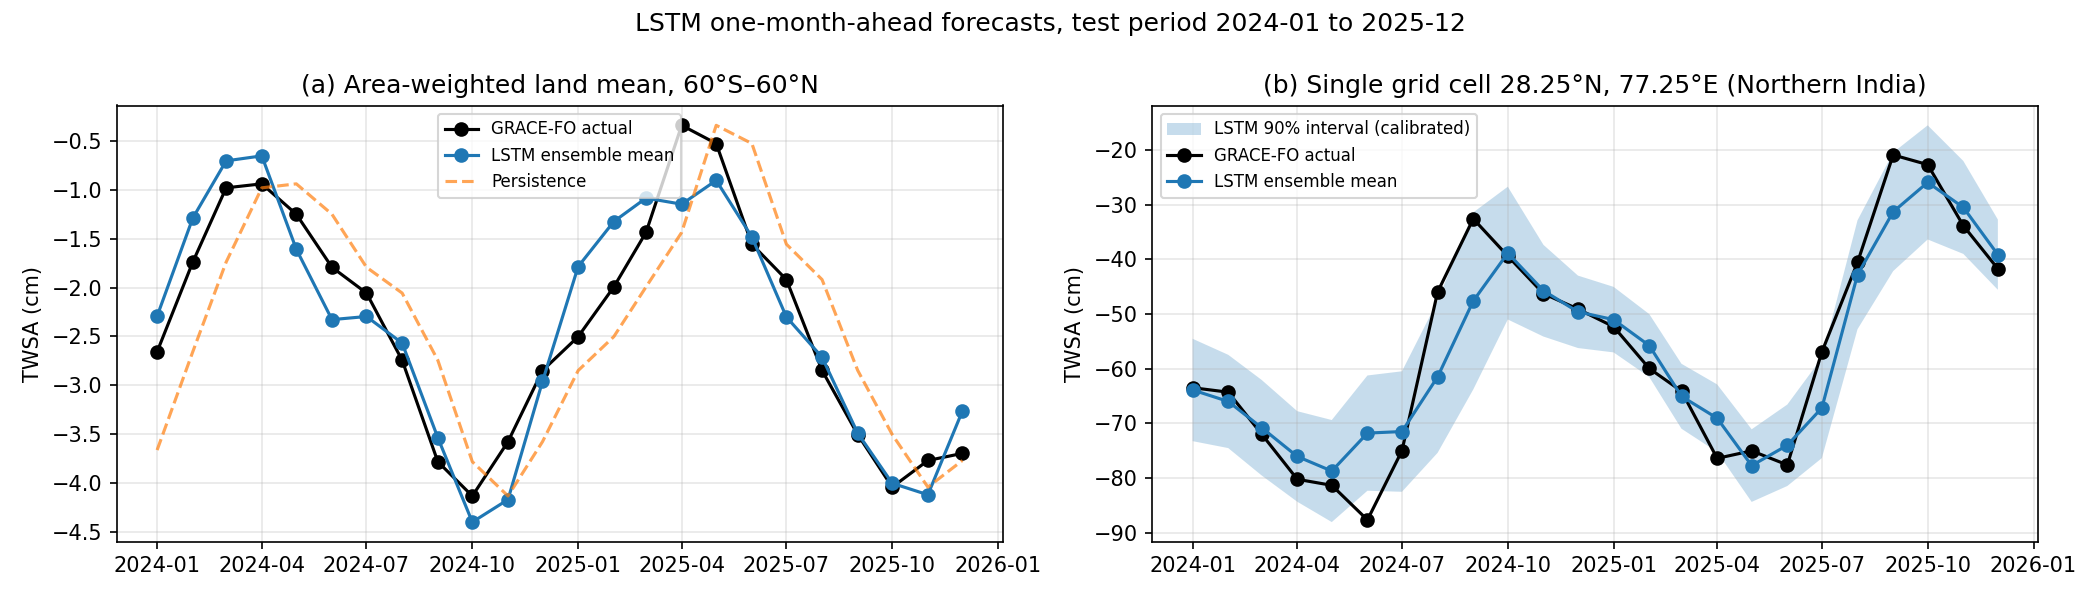

results/figures/lstm_skill_maps.png


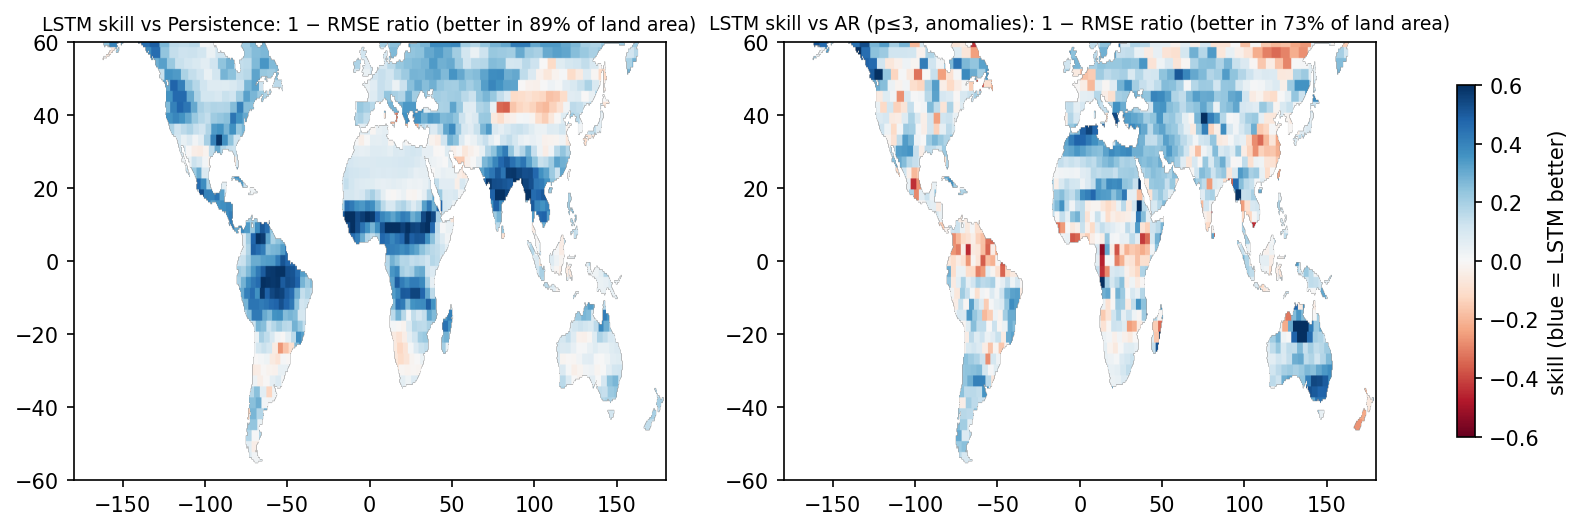

results/figures/lstm_interval_reliability.png


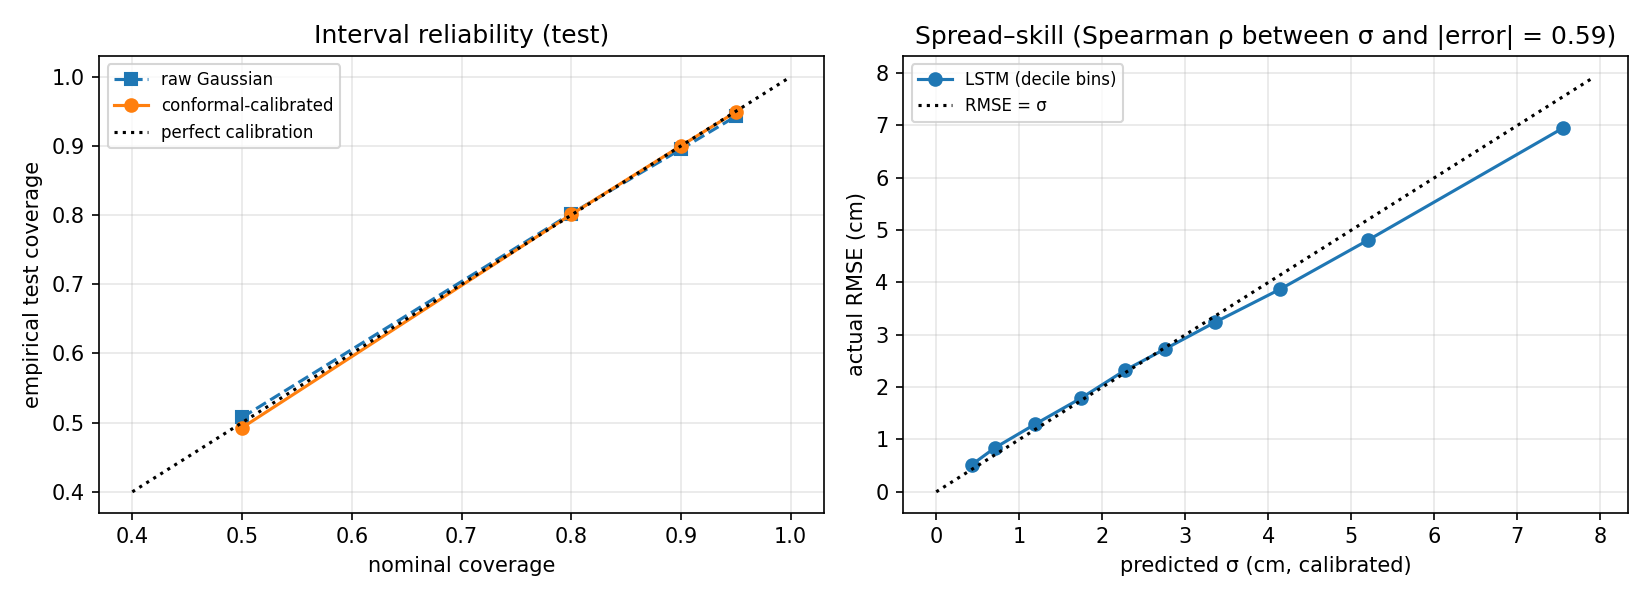

results/figures/lstm_aligned_grace_test_actual_vs_predicted.png


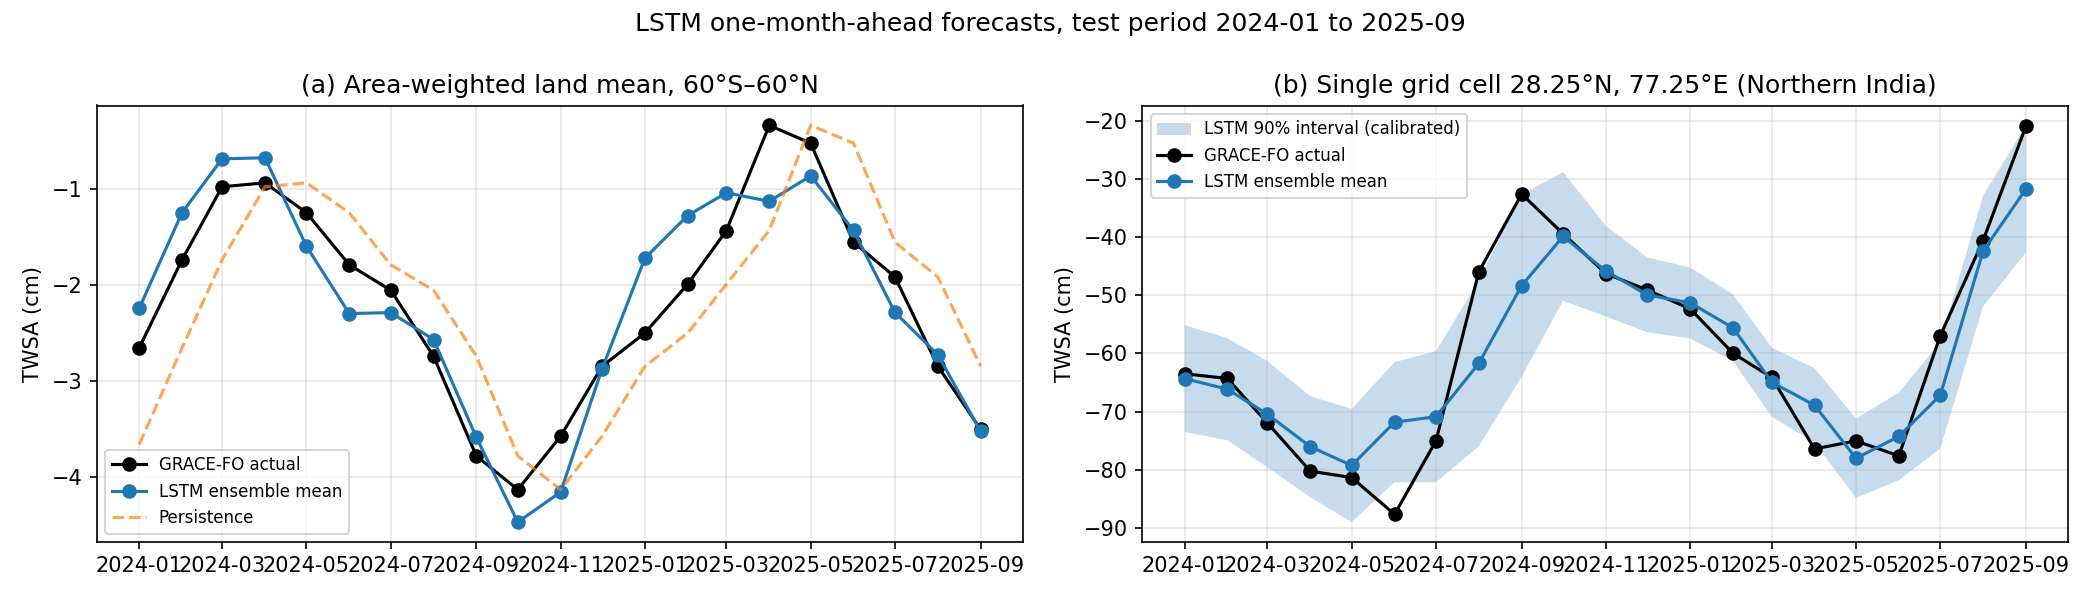

results/figures/lstm_aligned_grace_skill_maps.png


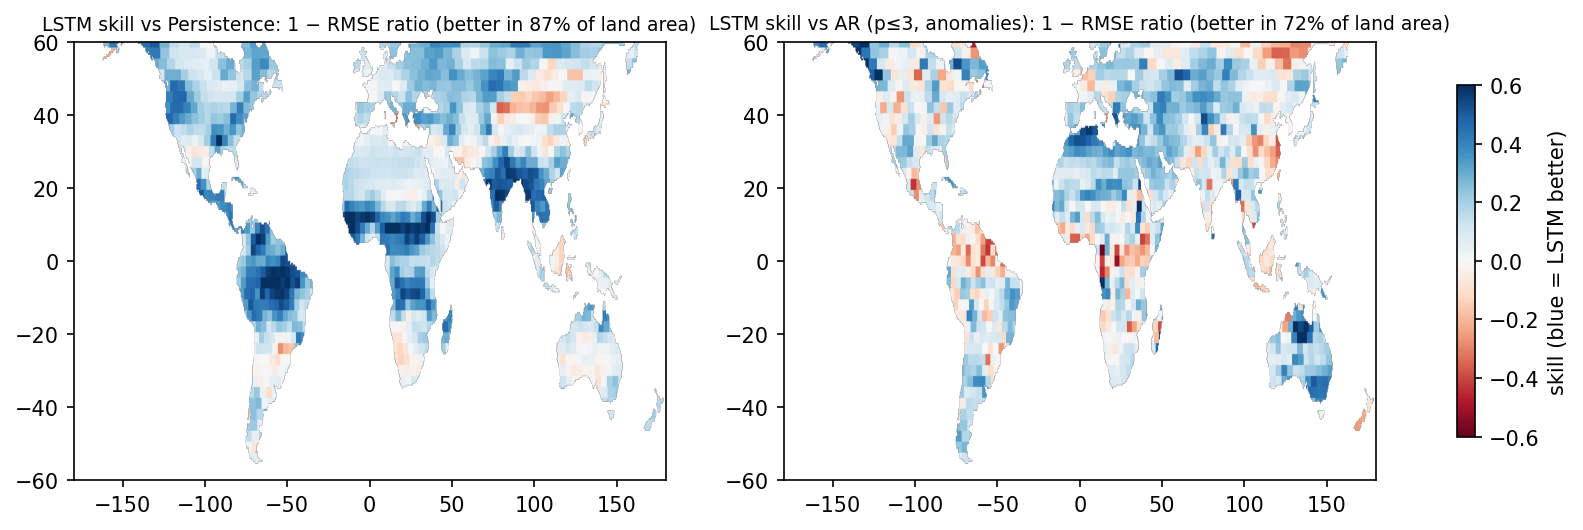

results/figures/lstm_aligned_grace_interval_reliability.png


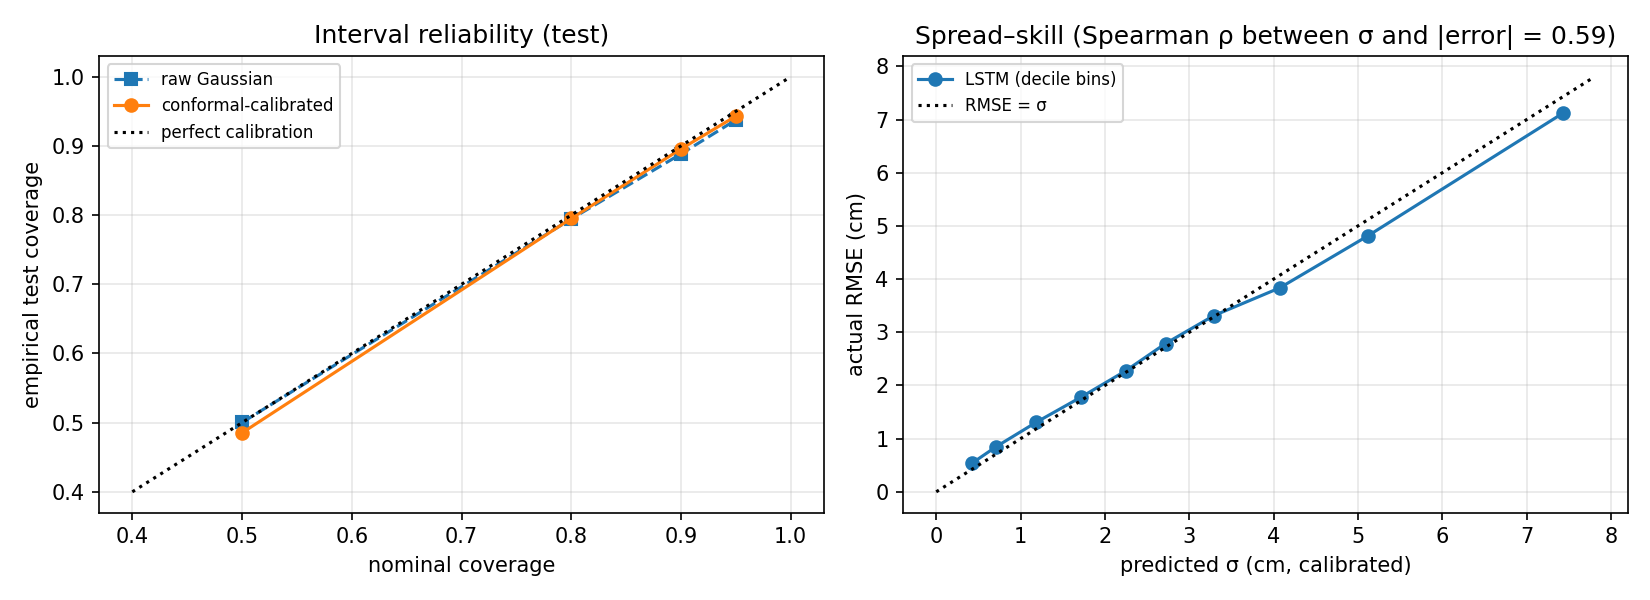

results/figures/lstm_aligned_combined_test_actual_vs_predicted.png


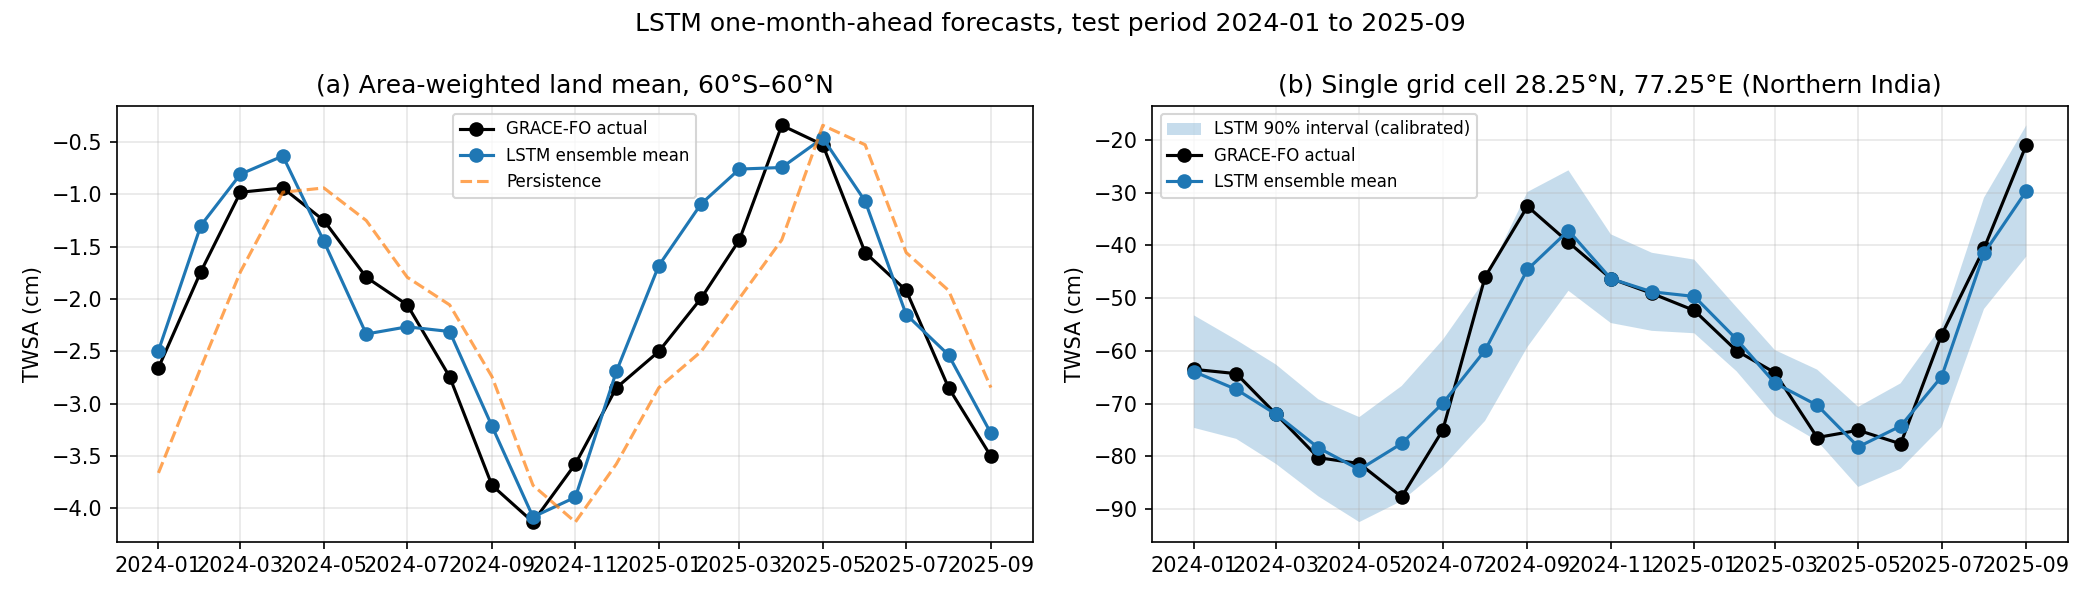

results/figures/lstm_aligned_combined_skill_maps.png


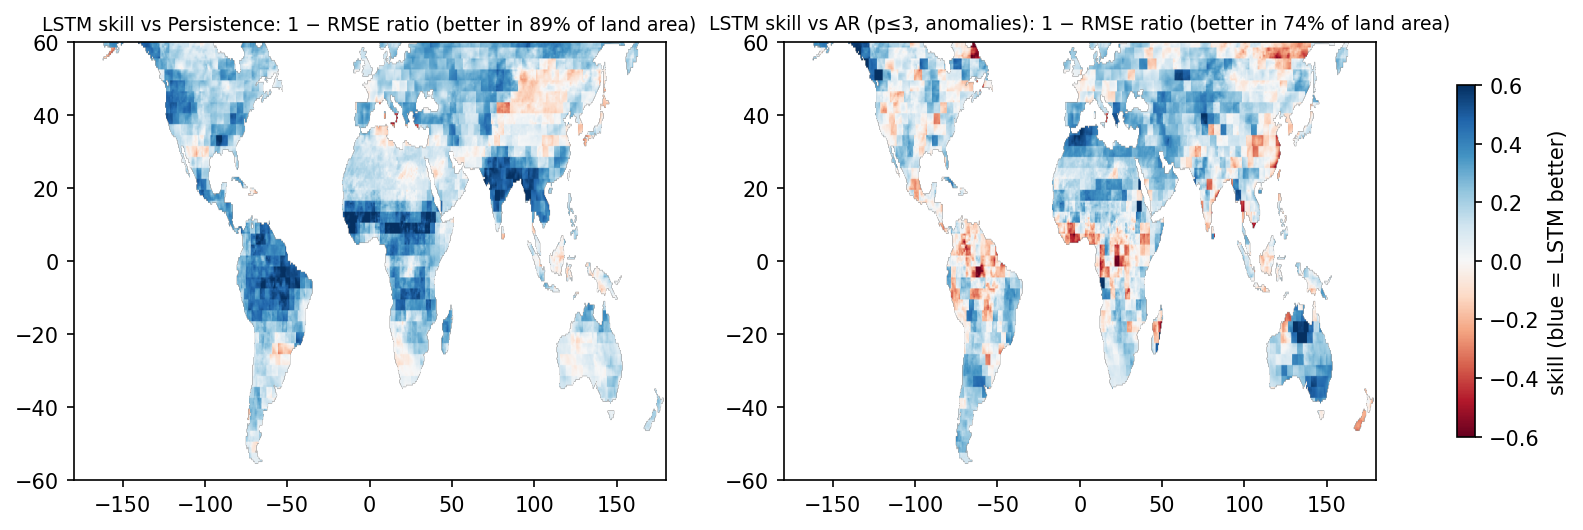

results/figures/lstm_aligned_combined_interval_reliability.png


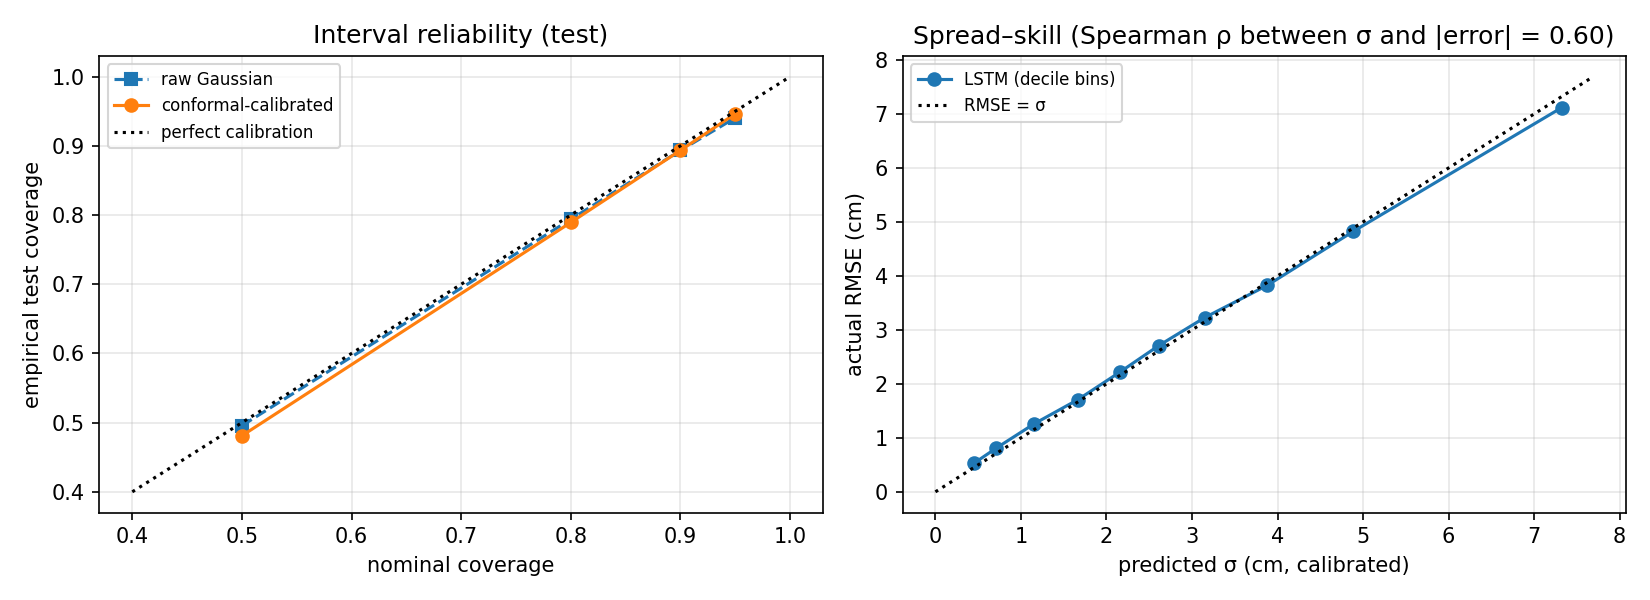

In [8]:
for prefix in runs:
    for name in ["test_actual_vs_predicted", "skill_maps", "interval_reliability"]:
        path = f"results/figures/{prefix}_{name}.png"
        if os.path.exists(path):
            print(path)
            display(Image(path))